In [1]:

!pip install easyocr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 68.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 5.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [easyocr]


In [2]:

import easyocr
from google.colab import files
from IPython.display import display, Image
from pathlib import Path


In [3]:

reader = easyocr.Reader(['en'], gpu=False)


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR model loaded successfully!


Saving mile.png to mile (2).png
Image path: mile (2).png


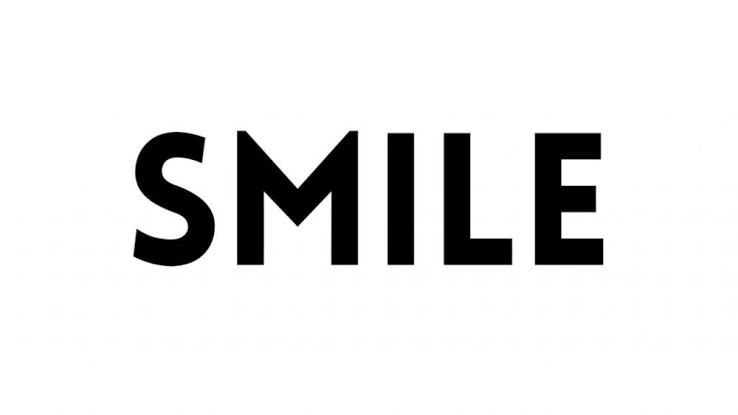

In [16]:

from google.colab import files
from IPython.display import display, Image

uploaded = files.upload()

image_path = next(iter(uploaded))

print("Image path:", image_path)
display(Image(filename=image_path))


In [17]:

results = reader.readtext(image_path)

print("OCR Results:\n")

for bbox, text, confidence in results:
    print(f"Text: {text}")
    print(f"Confidence: {confidence:.2%}")
    print("-" * 40)


OCR Results:

Text: SMILE
Confidence: 99.98%
----------------------------------------


In [10]:

texts = reader.readtext(image_path, detail=0)

extracted_text = "\n".join(texts)

print(extracted_text)


SMILE


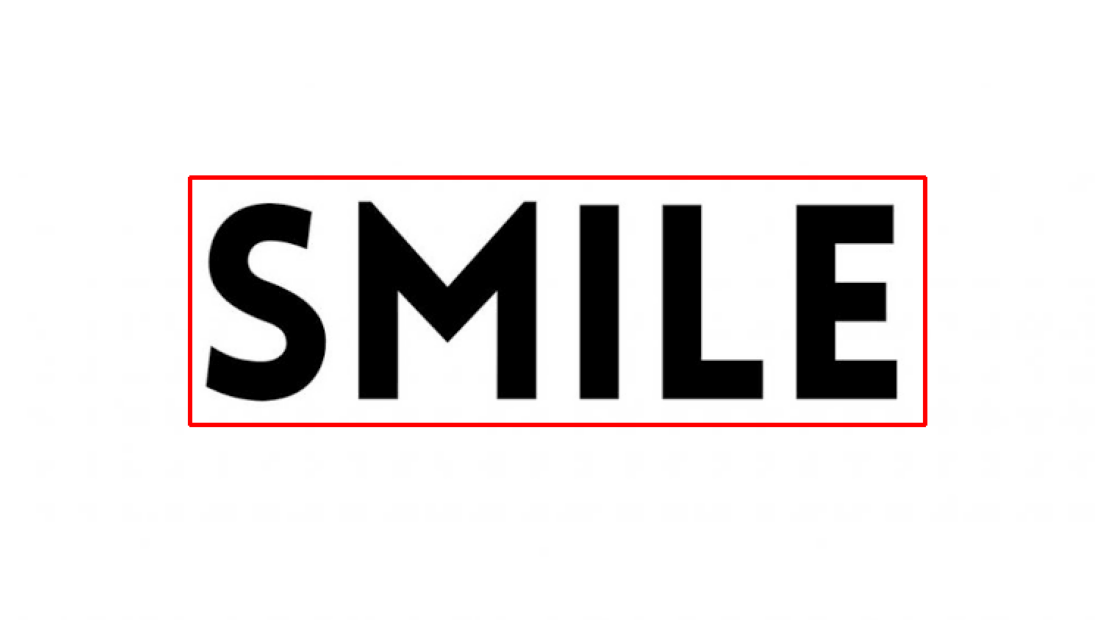

In [11]:

import cv2
import matplotlib.pyplot as plt

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for bbox, text, confidence in results:
    points = [(int(x), int(y)) for x, y in bbox]

    for i in range(4):
        cv2.line(
            image,
            points[i],
            points[(i + 1) % 4],
            (255, 0, 0),
            2
        )

plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.axis("off")
plt.show()
